In [ ]:
'''
i have to figure out which beginning-crm images work
cause some of them are messed up somehow
and then i will run them through colab to fix the coordinates

'''

In [1]:
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt
import os
import subprocess
from astropy.wcs import WCS

In [21]:
#matplotlib defaults
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [ ]:
#i guess we can look at the training data? maybe
#just the 1020 ones? or idk maybe both
#but then we definitely also want the science ones
#i guess i could save them all together

In [5]:
#training data
training_path = '/lustre/lrspec/ZTF_data/training_aug24/implant_train'
all_data_path = '/lustre/lrspec/ZTF_data/2022/1020'
inference_path = '/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras'

In [17]:
training_filenames = []

files = [
    f for f in os.listdir(training_path) if f.startswith("ztf_20221020")
]  # Adjust this to your file format
for file in files:
    image_filename = os.fsdecode(file)
    image_filename_start = image_filename[:-13]
    if len(training_filenames)>0:
        if image_filename_start in training_filenames:
            continue
        else:
            training_filenames.append(image_filename_start)
    else:
        training_filenames.append(image_filename_start)


In [18]:
training_filenames

['ztf_20221020138241_000686_zi_c06_x',
 'ztf_20221020138241_000686_zi_c02_x',
 'ztf_20221020138241_000686_zi_c05_x',
 'ztf_20221020138241_000686_zi_c01_x',
 'ztf_20221020138241_000686_zi_c08_x',
 'ztf_20221020138241_000686_zi_c03_x',
 'ztf_20221020138241_000686_zi_c07_x',
 'ztf_20221020138241_000686_zi_c04_x']

In [ ]:
'''
to copy and paste:
scp shard@darwin.hpc.udel.edu:/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c04_x.fits.fz Downloads/

'''

In [23]:
for name in training_filenames:
    file = '/lustre/lrspec/ZTF_data/2022/1020/'+name+'.fits.fz'
    print(file)

/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c06_x.fits.fz
/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c02_x.fits.fz
/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c05_x.fits.fz
/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c01_x.fits.fz
/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c08_x.fits.fz
/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c03_x.fits.fz
/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c07_x.fits.fz
/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c04_x.fits.fz


/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c06_x.fits.fz


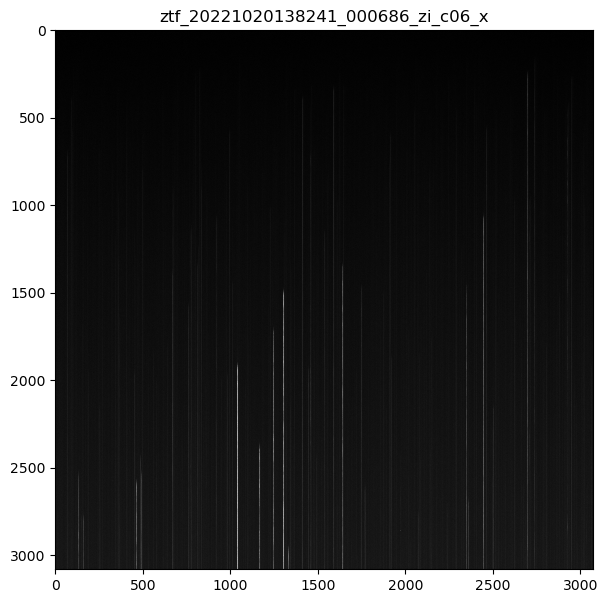

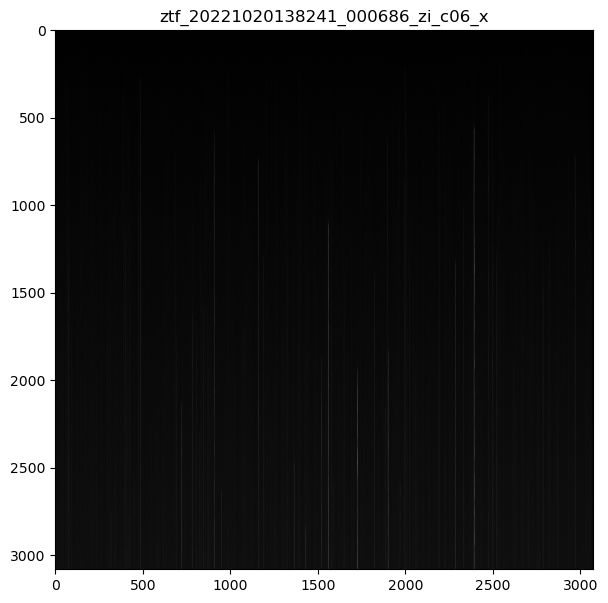

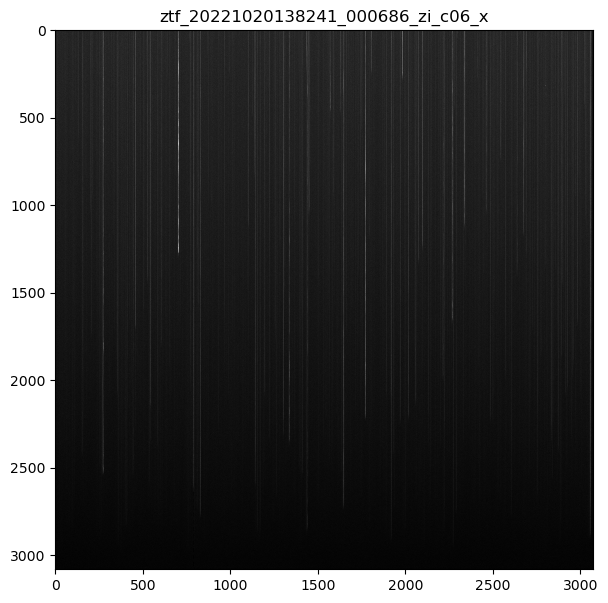

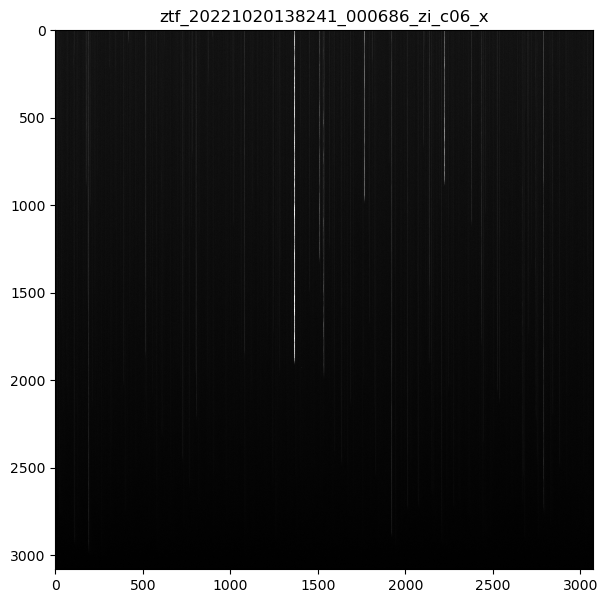

/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c02_x.fits.fz


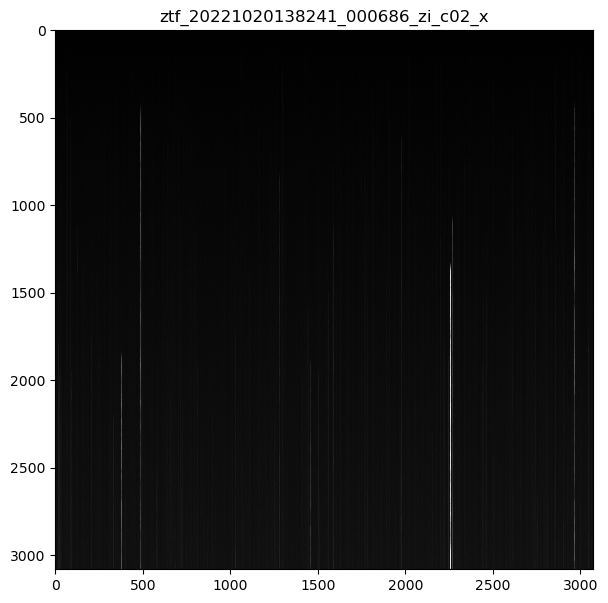

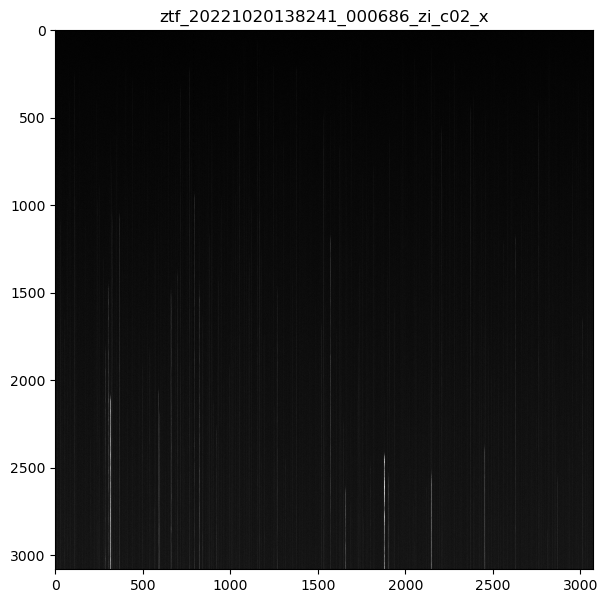

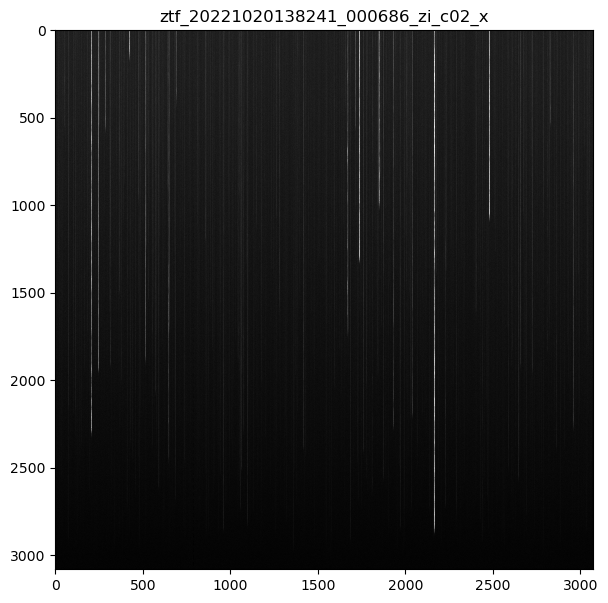

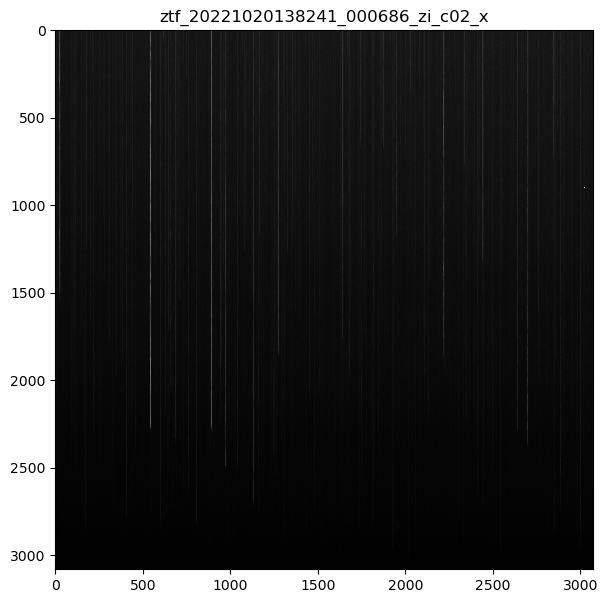

/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c05_x.fits.fz


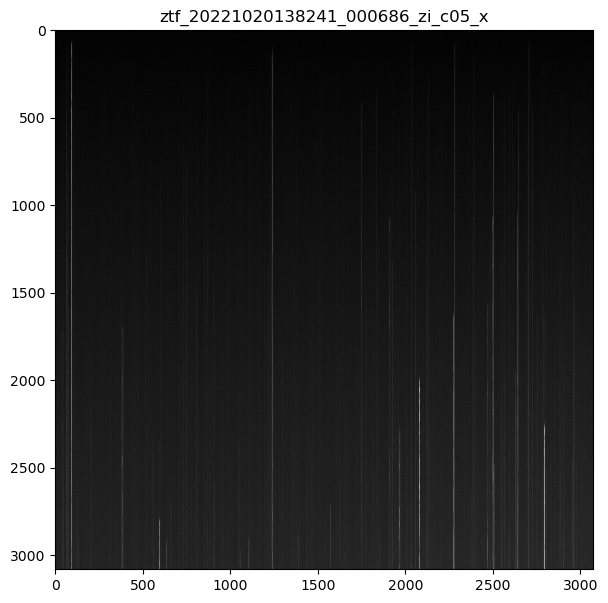

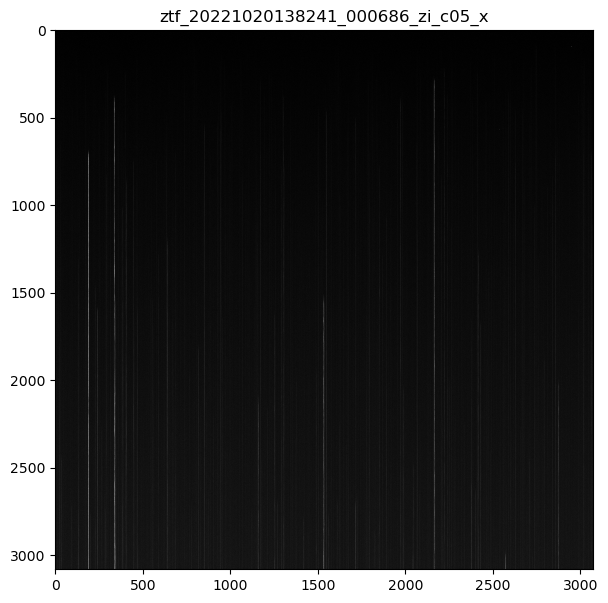

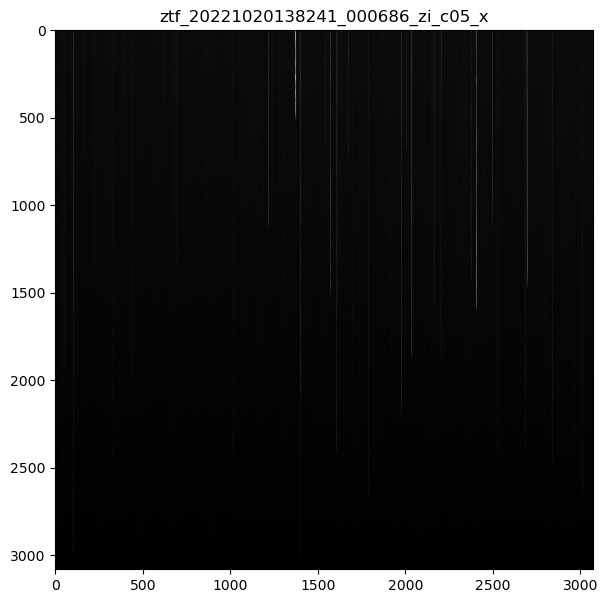

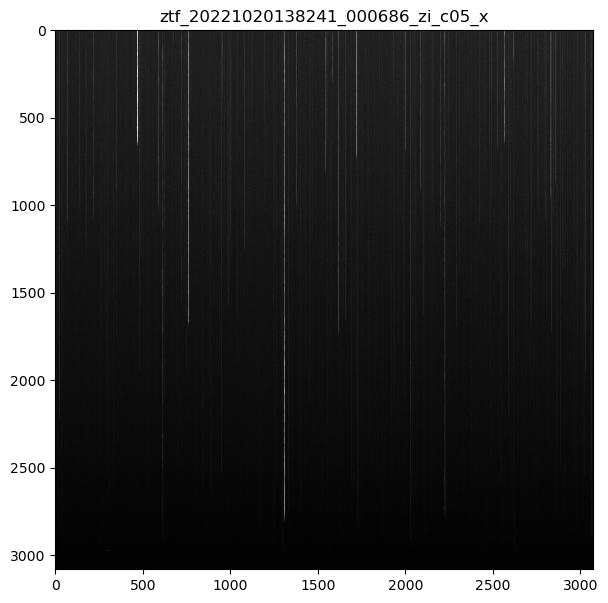

/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c01_x.fits.fz


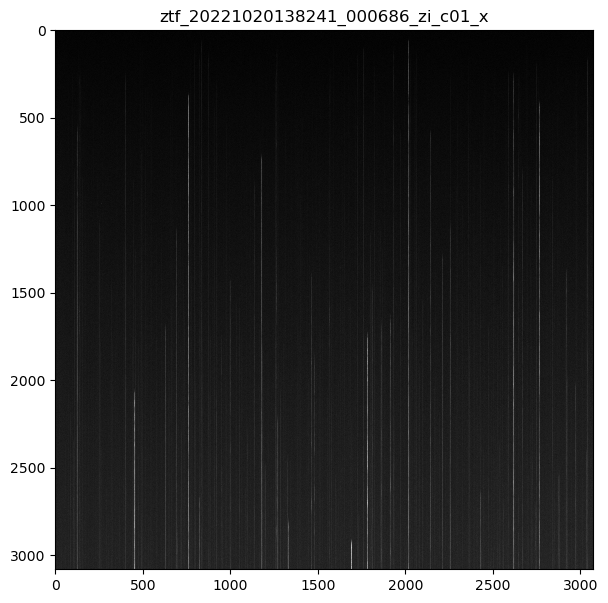

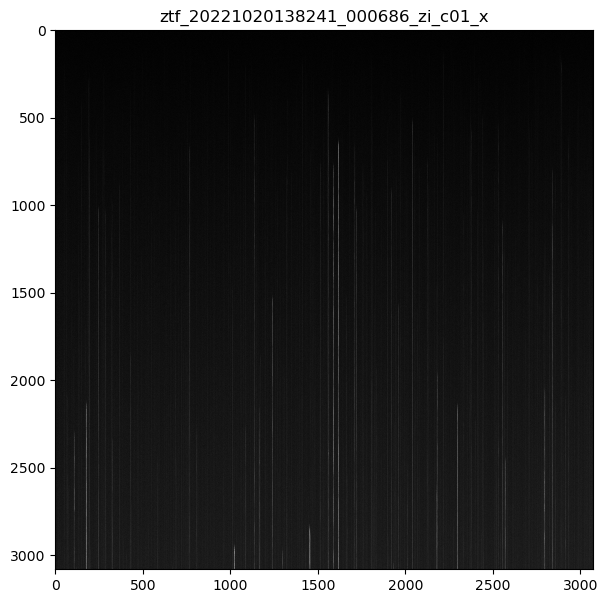

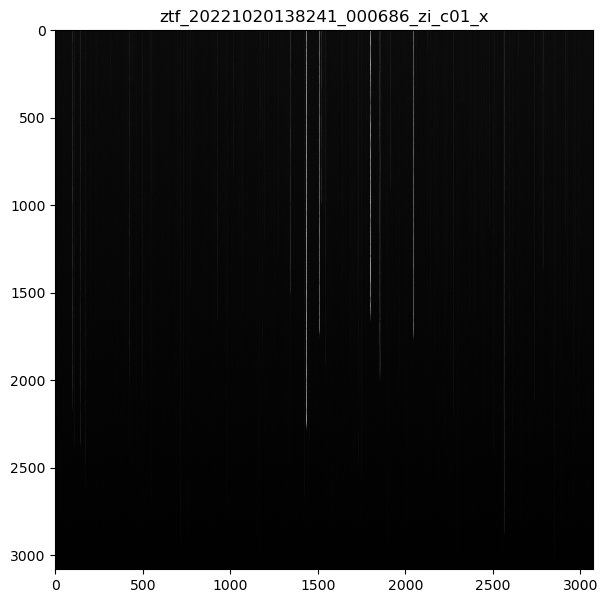

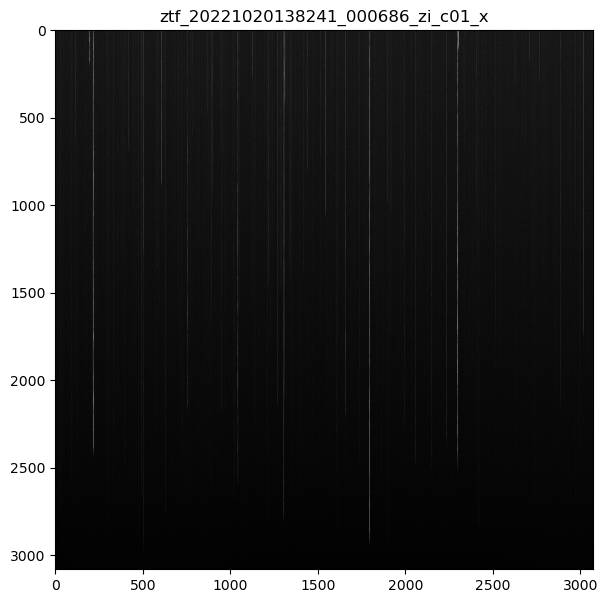

/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c08_x.fits.fz


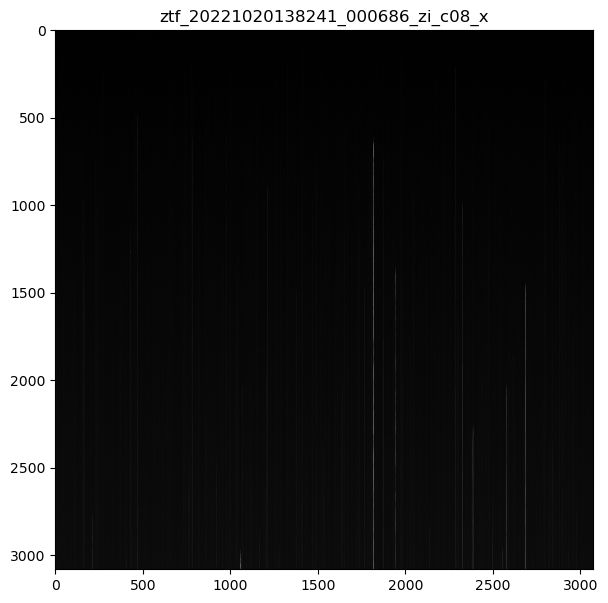

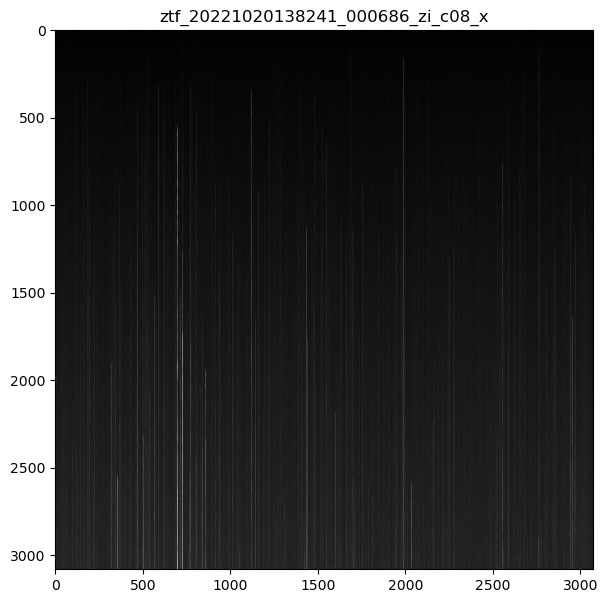

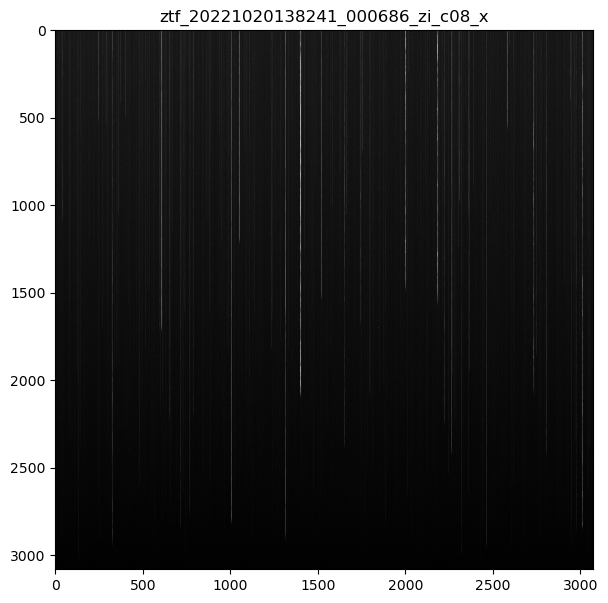

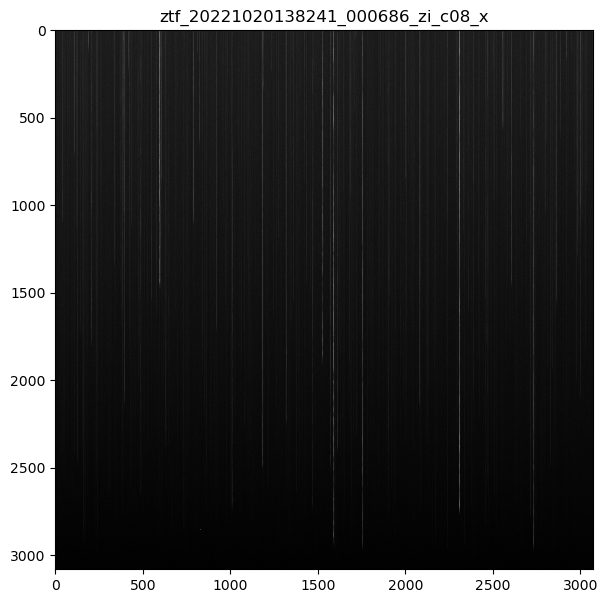

/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c03_x.fits.fz


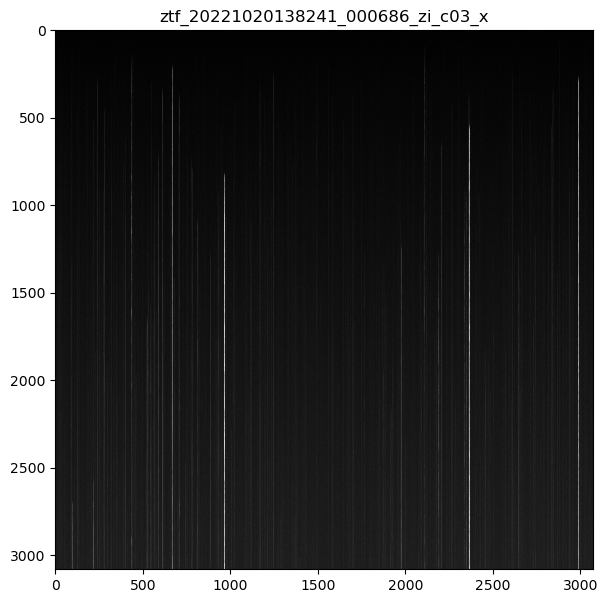

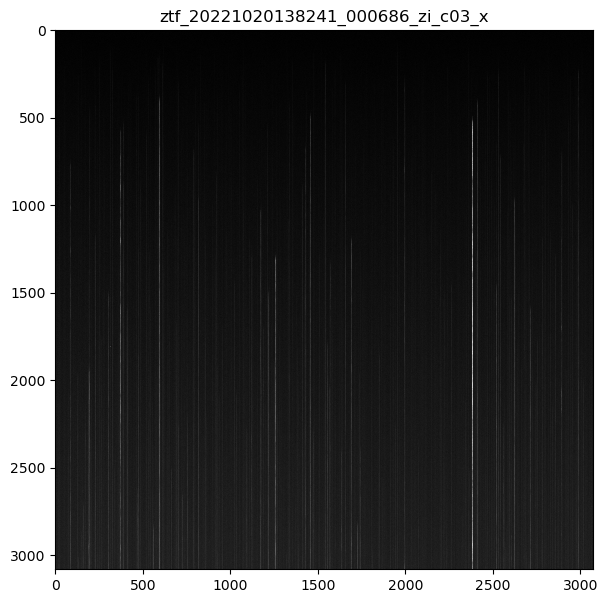

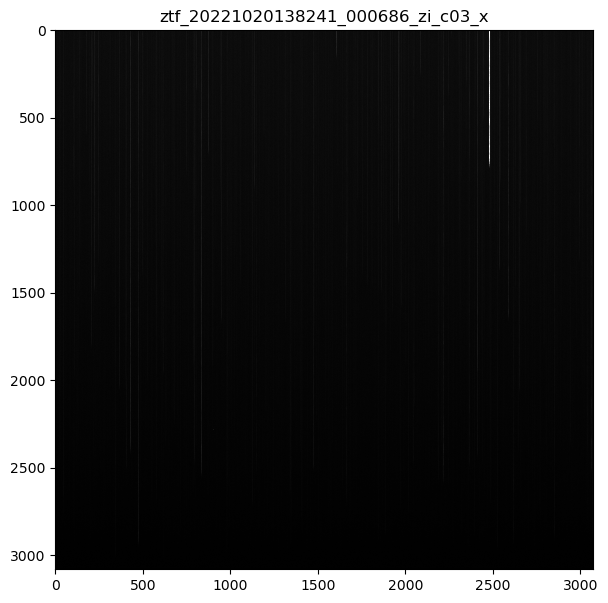

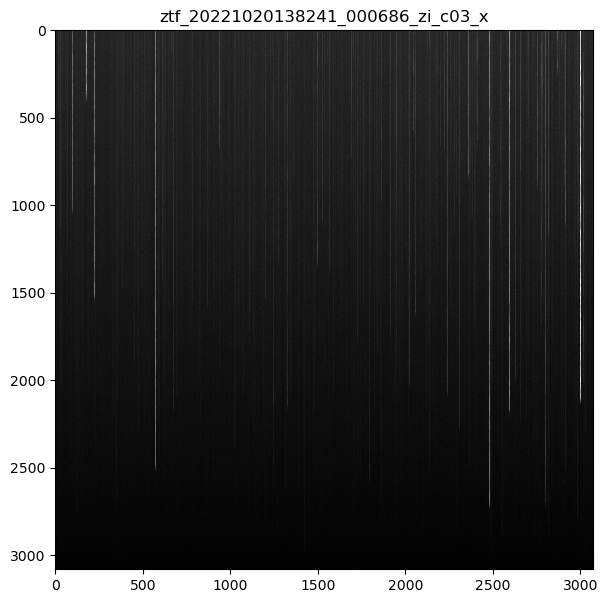

/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c07_x.fits.fz


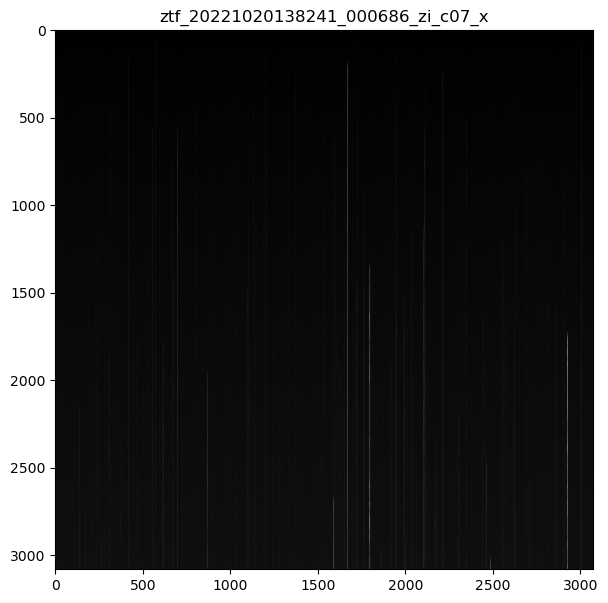

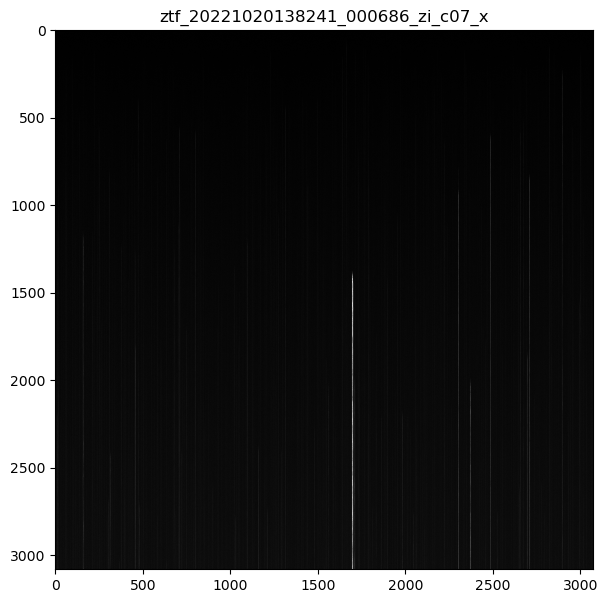

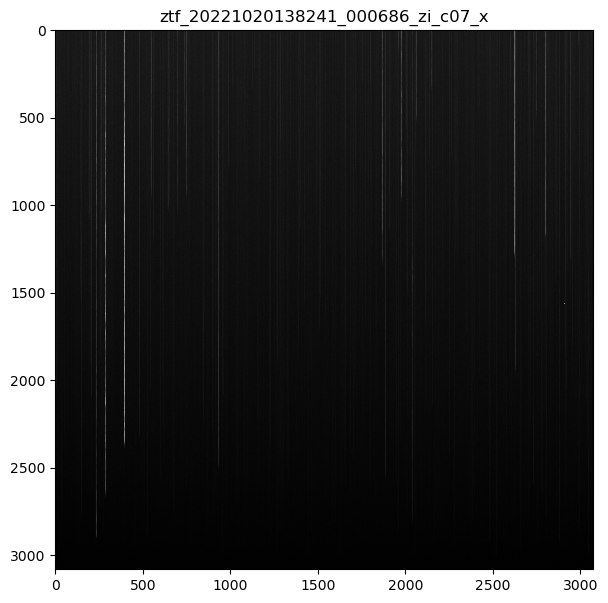

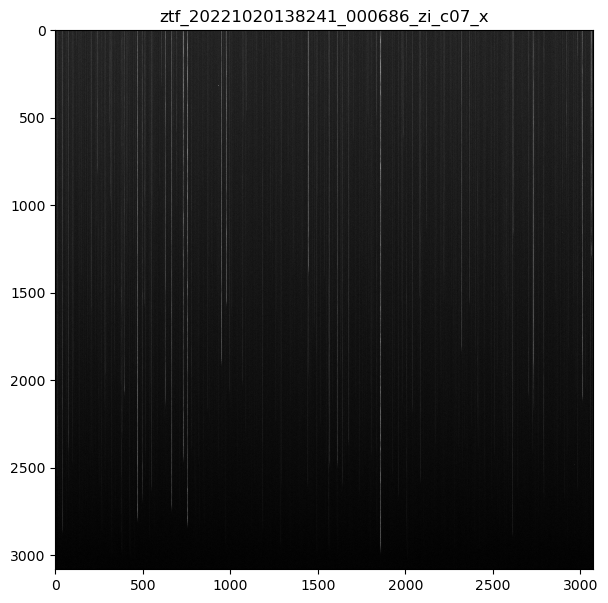

/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c04_x.fits.fz


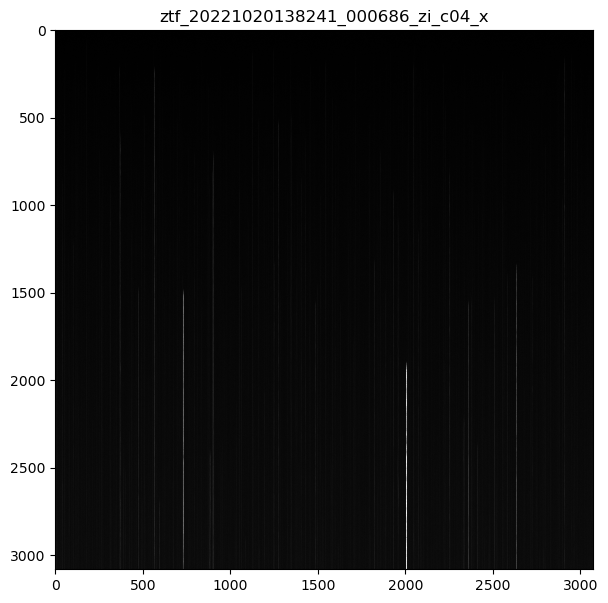

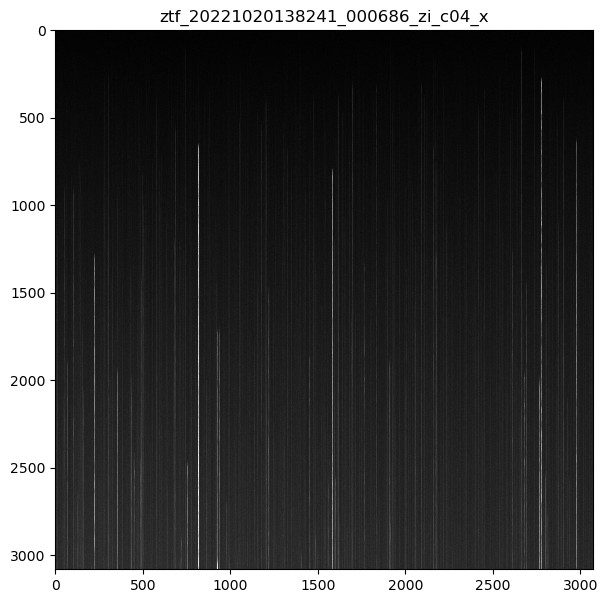

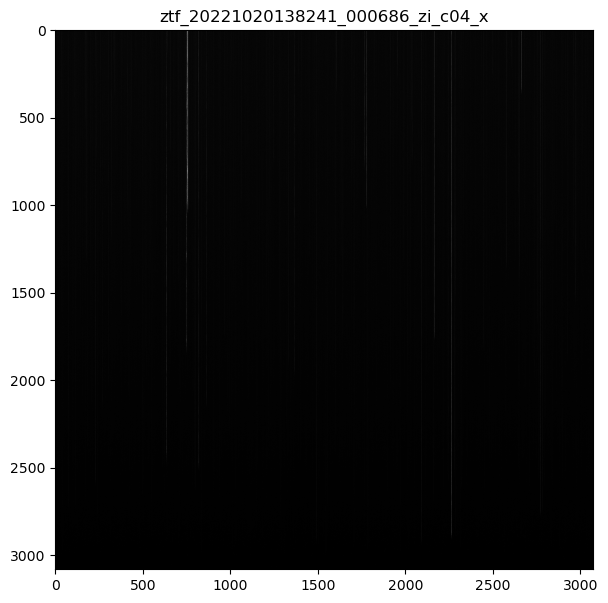

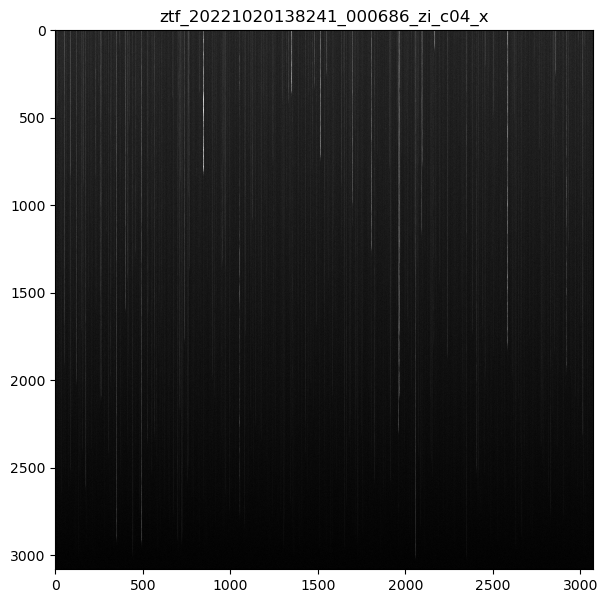

In [22]:
# for name in training_filenames:
#     file = '/lustre/lrspec/ZTF_data/2022/1020/'+name+'.fits.fz'
#     print(file)
#     hdul = fits.open(file)
#     for i in range(1,5):
#         plt.imshow(np.sqrt(hdul[i].data))
#         plt.title(name)
#         plt.show()
# #they all look legit and not messed up

In [ ]:
#we can calculate the xylists here probs

In [38]:
'''
Now we're going to calculate where the beginnings of the brightest streaks are.
To do this, we take the rolling mean along each column
and see when it changes by >70 over a different of ~100 pixels
(both of these parameters can be adjusted, but these ones work for me)

and it keeps the position of the greatest change
note that pixels separated by <8 are considered to be part of the same streak
note too that in the case of overlapping streaks, only the brighter one is retained
(this is because the inherent variability of some streaks is quite high,
and allowing more than one position along each streak meant that there were
too many which were clearly not from new stars)

this cell will take a while to run
'''
def get_diffs(array, quad):
    diffs = []
    for x_coord in range(np.shape(array)[1]):
        if quad==1 or quad==2: #moving from top to bottom if we have quad 1 or 2
            columns = range(0, np.shape(array)[0]-220)
        elif quad==3 or quad==4: #moving from bottom to top if we have quad 3 or 4
            columns = range(np.shape(array)[0]-220, 0, -1)
        for i in columns:
            mean_1 = np.mean(array[i:i+100,x_coord])
            mean_2 = np.mean(array[i+120:i+220,x_coord])
            if quad==1 or quad==2:
                diff = mean_2-mean_1
            else:
                diff = mean_1-mean_2
            if diff>30: #diff>100 did not give us enough stars for astrometry.net to be confident
                if len(diffs)>0:
                    last_x_coord = diffs[-1][0]
                    last_y_coord = diffs[-1][1]
                    last_diff = diffs[-1][2]
                    if np.abs(x_coord-last_x_coord) < 8:
                        # if np.abs((i+40)-last_y_coord) > 100 and diff>last_diff: #new star starting partway
                        #     diffs.append(np.array((x_coord,i+100, diff)))
                        # else:
                        if last_diff < diff:
                            diffs[-1]=np.array((x_coord,i+100, diff)) #replace if this is just a brighter version of the last one
                        else: #if the last one was brighter and they're the same, just ignore this one
                            continue
                    else:
                        diffs.append(np.array((x_coord,i+100, diff)))
                else:
                    diffs.append(np.array((x_coord,i+100, diff)))
            continue
    return diffs

/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c06_x.fits.fz


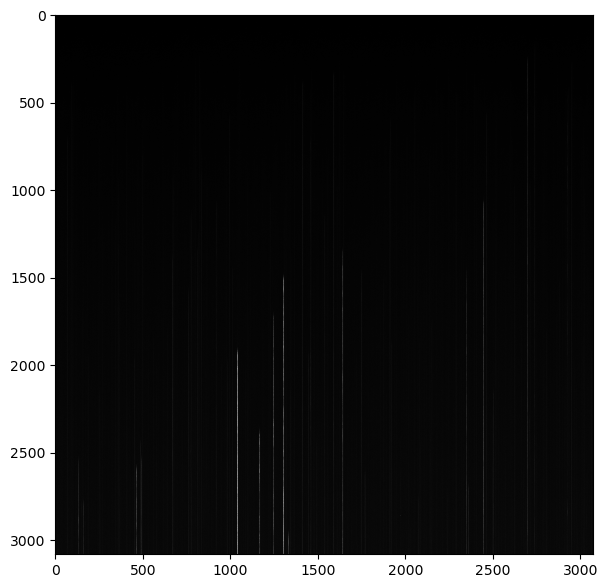

In [26]:
# for name in training_filenames:
#     file = '/lustre/lrspec/ZTF_data/2022/1020/'+name+'.fits.fz'
#     print(file)
#     hdul_start = fits.open(file)
#     for quad in range(1,5):
#         array = hdul_start[quad].data
#         break
#     break
# plt.imshow(array)
# # plt.scatter(np.array(diffs)[:,0], np.array(diffs)[:,1])

In [27]:
# diffs = get_diffs(array,quad)

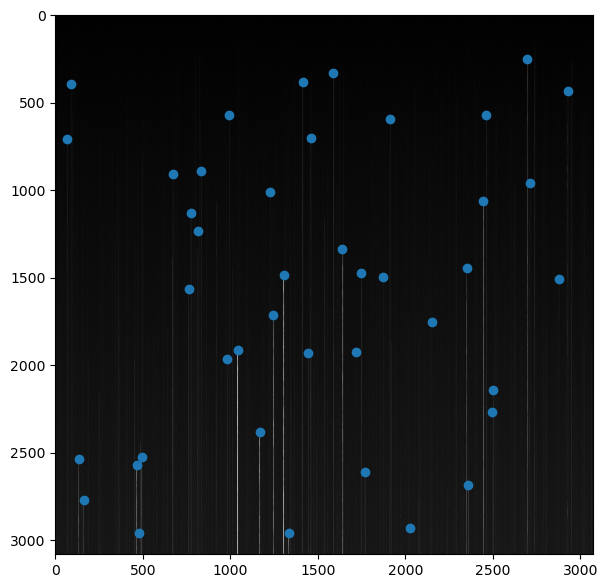

In [29]:
# plt.scatter(np.array(diffs)[:,0], np.array(diffs)[:,1])
# plt.imshow(np.sqrt(array))

In [32]:
#we have to convert this into a fits bintable file

def write_xylist(diffs, output_file):
    """
    Writes an XY list file from a given star catalog.
    """
    diffs = np.array(diffs)
    sorted_arr = diffs[diffs[:, 2].argsort()[::-1]]

    # Create FITS columns
    col1 = fits.Column(name='X', format='D', array=sorted_arr[:, 0])
    col2 = fits.Column(name='Y', format='D', array=sorted_arr[:, 1])

    # Create a FITS BINTABLE
    cols = fits.ColDefs([col1, col2])
    hdu = fits.BinTableHDU.from_columns(cols)

  # Save to a FITS file
    hdu.writeto(output_file+'.fits', overwrite=True)
    print(f"XY list saved to {output_file}.fits")

In [33]:
# #here is where we do all the stuff


# xy_file = "/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/"+name+"_"+str(quad) #you can give this a more descriptive name
# write_xylist(diffs, xy_file)

XY list saved to /lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c06_x_1.fits


In [41]:
hdul_xylist = fits.open('/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c06_x_1.fits')

In [44]:
hdul_xylist[1].data

FITS_rec([(1168., 2379.), (1042., 1915.), (2695.,  248.), (1769., 2609.),
          (1304., 1482.), ( 775., 1131.), (1246., 1711.), (1334., 2959.),
          (1640., 1337.), (1748., 1470.), ( 465., 2572.), ( 133., 2534.),
          (2446., 1060.), (  68.,  709.), (1445., 1929.), ( 478., 2959.),
          ( 672.,  909.), (1226., 1010.), (2350., 1444.), ( 493., 2522.),
          (2927.,  434.), (2461.,  567.), (1459.,  698.), ( 162., 2770.),
          ( 816., 1232.), (2710.,  959.), (2361., 2681.), (1912.,  595.),
          (1589.,  329.), (2495., 2267.), ( 994.,  572.), ( 834.,  892.),
          ( 983., 1966.), (2503., 2142.), (1718., 1924.), (2150., 1751.),
          (1873., 1497.), (2026., 2927.), (1413.,  382.), ( 762., 1566.),
          (  91.,  393.), (2878., 1509.)],
         dtype=(numpy.record, [('X', '>f8'), ('Y', '>f8')]))

In [66]:
poses =  hdul_xylist[1].data
poses['X']

array([2393., 1163., 1728.,  787., 2477.,  696., 1192., 1561., 1905.,
       2004.,  911.,  723., 2825., 1522., 2286., 2973., 1971., 1430.,
        950.,  478., 1367., 2627., 1387., 1232., 2501.,  808., 1887.,
        826.,  394.,  592.,  403., 1329., 1824., 1867., 2049.,  488.,
       2078., 1075., 2520.,   76.,  847.,  992., 1577.,  872., 1267.,
       2404., 2057., 2789.,  838., 2332., 2704.,  322., 1590., 2667.,
       2169., 1622., 2618., 1318.,  412.,   93., 2537., 1240.,  372.,
       1947., 2766., 2224., 1443., 1810., 1653., 2340.])

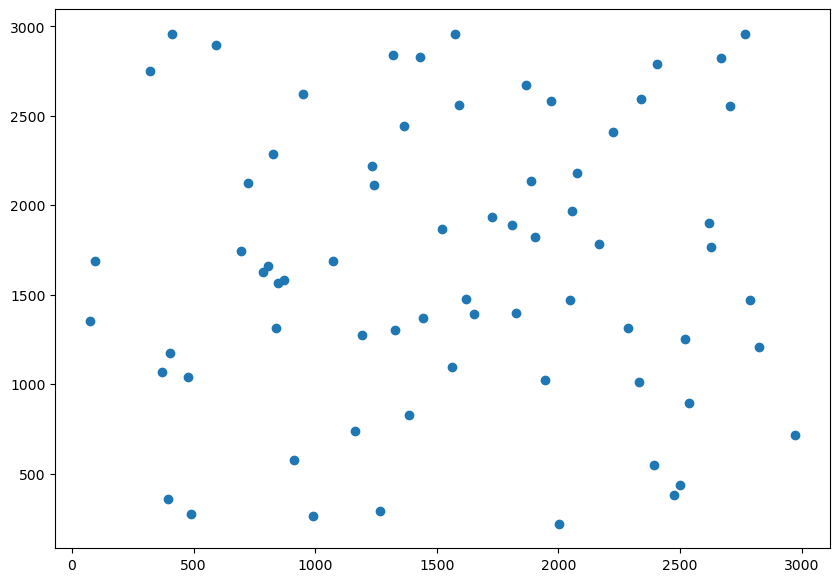

In [68]:
plt.scatter(hdul_xylist[1].data['X'],hdul_xylist[1].data['Y'])

In [45]:
hdul_xylist.info()

Filename: /lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c06_x_1.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1                1 BinTableHDU     12   42R x 2C   ['D', 'D']   


In [ ]:
for name in training_filenames:
    file = '/lustre/lrspec/ZTF_data/2022/1020/'+name+'.fits.fz'
    print(file)
    hdul_start = fits.open(file)
    for quad in range(1,5):
        array = hdul_start[quad].data
        xy_file = "/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/"+name+"_"+str(quad)
        # plt.imshow(np.sqrt(hdul_start[quad].data))
        diffs = get_diffs(array, quad)
        write_xylist(diffs, xy_file)

In [48]:
!ls /lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays

ztf_20221020138241_000686_zi_c06_x_1.fits
ztf_20221020138241_000686_zi_c06_x_2.fits


In [49]:
#check that it worked
for name in training_filenames:
    file = '/lustre/lrspec/ZTF_data/2022/1020/'+name+'.fits.fz'
    print(file)
    for quad in range(1,5):
        hdul_xylist = fits.open("/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/"+name+"_"+str(quad)+".fits")
        hdul_xylist.info()

/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c06_x.fits.fz
Filename: /lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c06_x_1.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1                1 BinTableHDU     12   75R x 2C   [D, D]   
Filename: /lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c06_x_2.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1                1 BinTableHDU     12   70R x 2C   [D, D]   


FileNotFoundError: [Errno 2] No such file or directory: '/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c06_x_3.fits'

/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c06_x.fits.fz


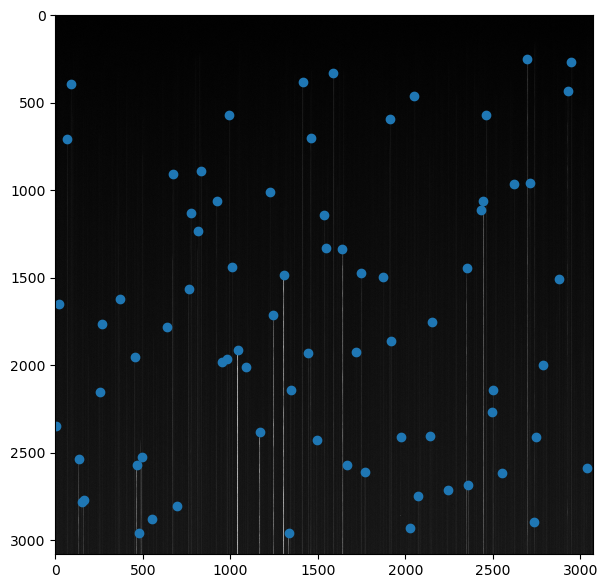

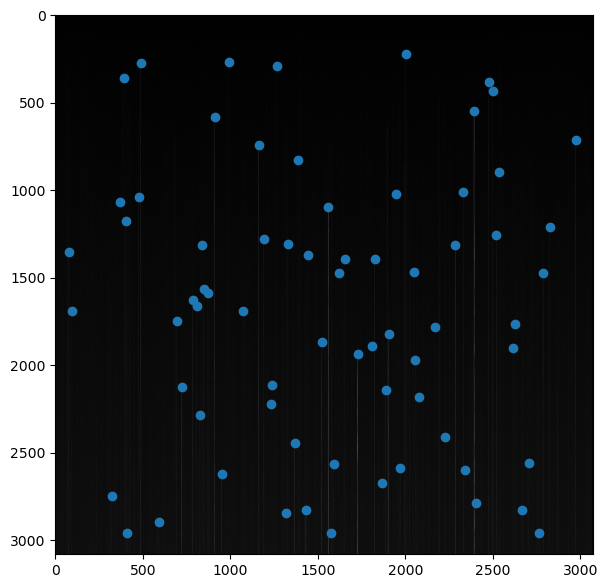

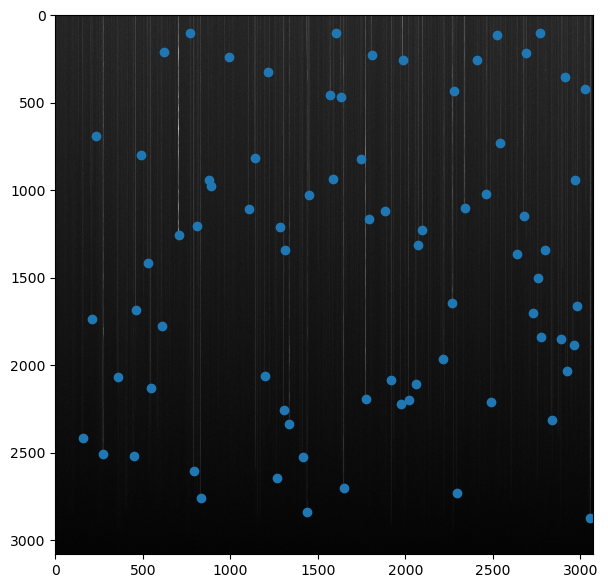

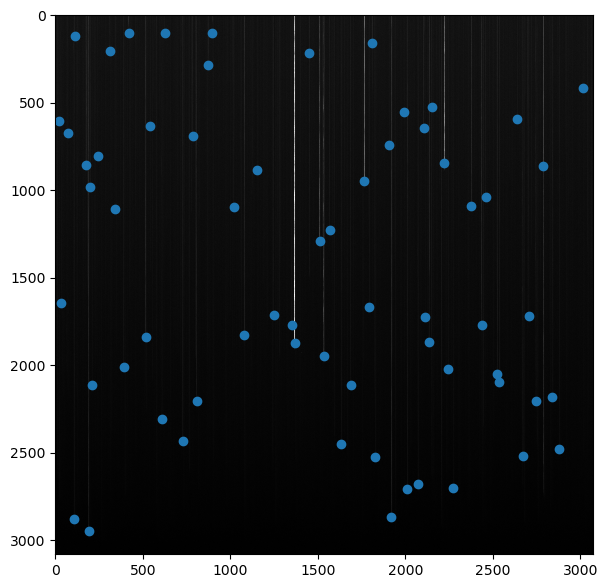

/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c02_x.fits.fz


FileNotFoundError: [Errno 2] No such file or directory: '/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c02_x_1.fits'

In [70]:
#check that it worked more in depth
for name in training_filenames:
    file = '/lustre/lrspec/ZTF_data/2022/1020/'+name+'.fits.fz'
    print(file)
    for quad in range(1,5):
        hdul_xylist = fits.open("/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/"+name+"_"+str(quad)+".fits")
        hdul_img = fits.open(file)
        plt.scatter(hdul_xylist[1].data['X'],hdul_xylist[1].data['Y'])
        plt.imshow(np.sqrt(hdul_img[quad].data))
        plt.show()

In [ ]:
#then i should zip it and then download
#then i can upload to google drive and then get all the wcs files
#rezip, reuupload
#i can write the processing while it's doing that...tomorrowish